**Project Title:Customer Churn Prediction Using Machine Learning**

**Project Description**

Customer Churn Prediction is a machine learning project that predicts whether a customer is likely to stop using a company's services.

For example, a telecom company wants to identify customers who may cancel their subscriptions. By analyzing customer information, such as monthly charges, contract type, tenure, and payment method, a machine learning model can predict the likelihood of churn.

Objective: Develop a complete machine learning solution to predict customer churn and help businesses improve customer retention.



# Dataset Description: Customer Churn Prediction Using Machine Learning

## 1. Introduction

The **IBM Telco Customer Churn dataset** is used in the Customer Churn Prediction project to analyze customer behavior and predict whether a customer is likely to leave a company.

The dataset contains customer demographic information, subscribed services, account details, billing information, and churn status. It helps identify the factors that may influence customers to discontinue a service.

The dataset contains approximately **7,043 customer records and 21 columns** in its commonly used version.

## 2. Dataset Features and Descriptions

The dataset columns can be divided into four main categories.

### A. Customer Information

| Column Name     | Description                                                           |
| --------------- | --------------------------------------------------------------------- |
| `customerID`    | Unique identification number assigned to each customer.               |
| `gender`        | Gender of the customer, such as Male or Female.                       |
| `SeniorCitizen` | Indicates whether the customer is a senior citizen (1 = Yes, 0 = No). |
| `Partner`       | Indicates whether the customer has a partner.                         |
| `Dependents`    | Indicates whether the customer has dependents.                        |

### B. Customer Service Information

| Column Name        | Description                                                                 |
| ------------------ | --------------------------------------------------------------------------- |
| `PhoneService`     | Indicates whether the customer subscribes to phone service.                 |
| `MultipleLines`    | Indicates whether the customer has multiple phone lines.                    |
| `InternetService`  | Type of internet service, such as DSL, Fiber optic, or No internet service. |
| `OnlineSecurity`   | Indicates whether online security is included.                              |
| `OnlineBackup`     | Indicates whether online backup is included.                                |
| `DeviceProtection` | Indicates whether device protection is included.                            |
| `TechSupport`      | Indicates whether technical support is included.                            |
| `StreamingTV`      | Indicates whether the customer subscribes to streaming TV.                  |
| `StreamingMovies`  | Indicates whether the customer subscribes to streaming movies.              |

### C. Account and Billing Information

| Column Name        | Description                                                    |
| ------------------ | -------------------------------------------------------------- |
| `tenure`           | Number of months the customer has stayed with the company.     |
| `Contract`         | Contract type: Month-to-month, One year, or Two year.          |
| `PaperlessBilling` | Indicates whether the customer uses paperless billing.         |
| `PaymentMethod`    | Method used to pay bills.                                      |
| `MonthlyCharges`   | Amount charged to the customer each month.                     |
| `TotalCharges`     | Total charges accumulated over the customer's account history. |

### D. Target Variable

| Column Name | Description                                                                   |
| ----------- | ----------------------------------------------------------------------------- |
| `Churn`     | Indicates whether the customer left the company (Yes = Churn, No = No Churn). |

**The `Churn` column is the target variable** used to train the machine learning model.

* `Yes` — The customer has left the company.
* `No` — The customer has remained with the company.




**Import Required Libraries**

In [158]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine learning models

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier


# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Save the model
import joblib

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


**Load the Dataset**

In [159]:
# Load dataset
churn_data = pd.read_csv('/content/Telco-Customer-Churn.csv')
#Display the records
churn_data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [160]:
#shape of the dataset
churn_data.shape

(7043, 21)

In [161]:
#isplay column names
churn_data.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

**Understand the Dataset**

In [162]:
#general information about the dataset
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [163]:
#statistical information about the dataset
churn_data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [164]:
# Check the target variable
print(churn_data["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [165]:
# Check target percentages
print((churn_data["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


**Data Preprocessing**

In [166]:
# Make a copy of the original dataset
churn_data = churn_data.copy()

In [167]:
# Remove duplicate rows
churn_data = churn_data.drop_duplicates()

In [168]:
# Remove unnecessary spaces from column names
churn_data.columns =churn_data.columns.str.strip()

In [169]:
# Convert TotalCharges to numeric,because some records may contain blank strings
churn_data["TotalCharges"] = pd.to_numeric(
    churn_data["TotalCharges"],
    errors="coerce"
)

In [170]:
# Check missing values
print("Missing values before preprocessing:")
print(churn_data.isnull().sum())


Missing values before preprocessing:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [171]:
# Check duplicate records
print("\nDuplicate records:", churn_data.duplicated().sum())


Duplicate records: 0


In [172]:
# Check target values
print("\nChurn values:")
print(churn_data["Churn"].value_counts(dropna=False))


Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [173]:
# Remove records with a missing target
churn_data = churn_data.dropna(subset=["Churn"])

In [174]:
# Remove rows with an invalid target value
churn_data = churn_data[churn_data["Churn"].isin(["Yes", "No"])]

In [175]:
print("\nDataset shape after basic cleaning:", churn_data.shape)


Dataset shape after basic cleaning: (7043, 21)


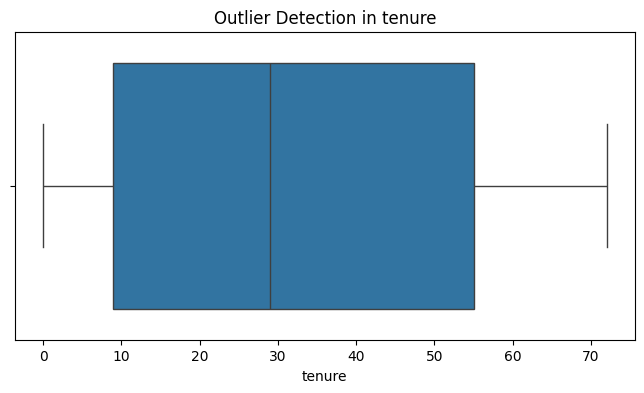

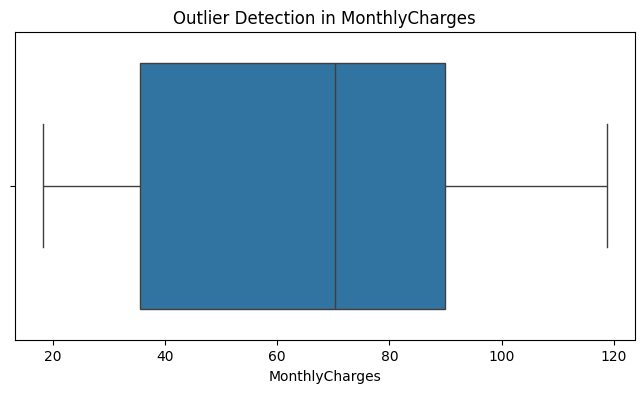

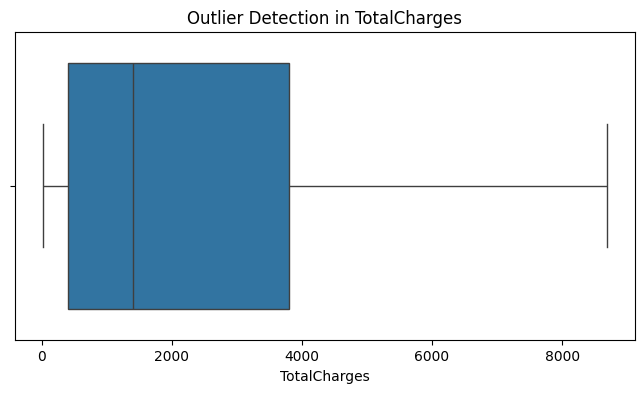

In [176]:
# Outlier detection

# Numerical columns to check
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

# Display boxplots
for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=churn_data[column])
    plt.title(f"Outlier Detection in {column}")
    plt.show()

**Exploratory Data Analysis (EDA)**

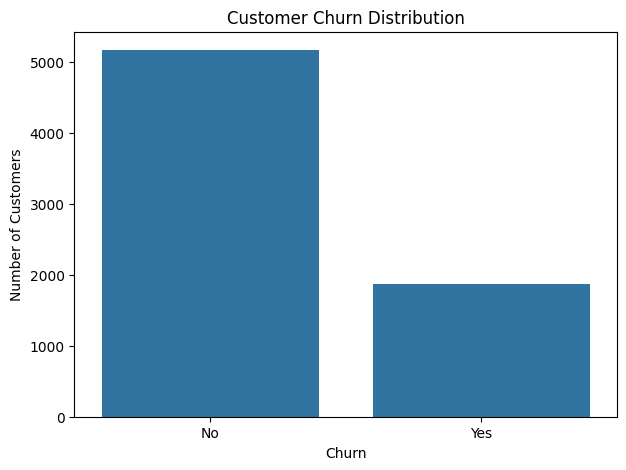

In [177]:
#Churn Distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=churn_data, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


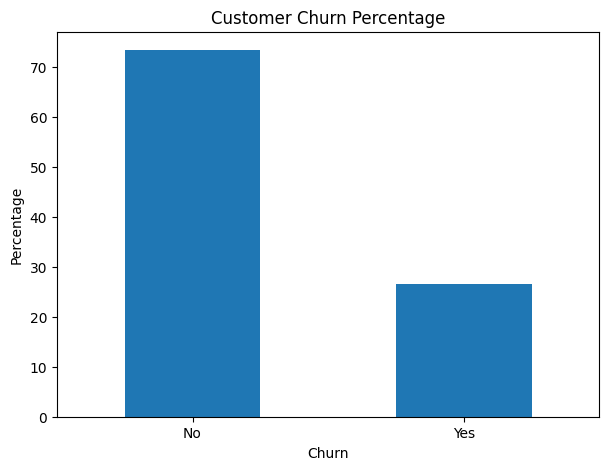

In [178]:
#Churn Percentage
churn_percentage = (
    churn_data["Churn"]
    .value_counts(normalize=True)
    .mul(100)
)

print(churn_percentage.round(2))

churn_percentage.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Customer Churn Percentage")
plt.xlabel("Churn")
plt.ylabel("Percentage")
plt.xticks(rotation=0)

plt.show()

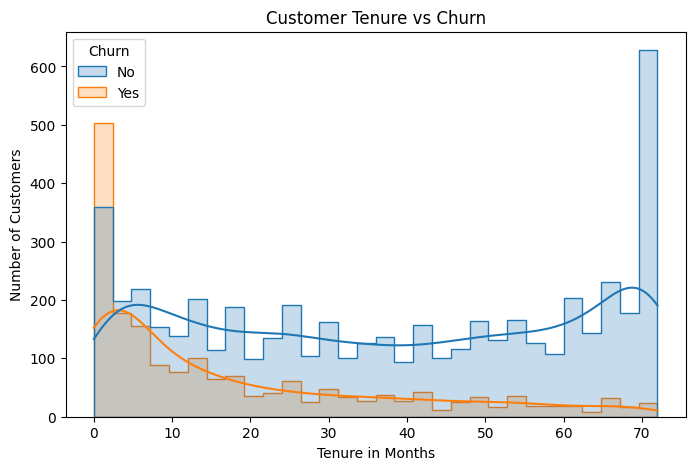

In [179]:
#Customer Tenure Analysis
plt.figure(figsize=(8, 5))

sns.histplot(
    data=churn_data,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure in Months")
plt.ylabel("Number of Customers")

plt.show()

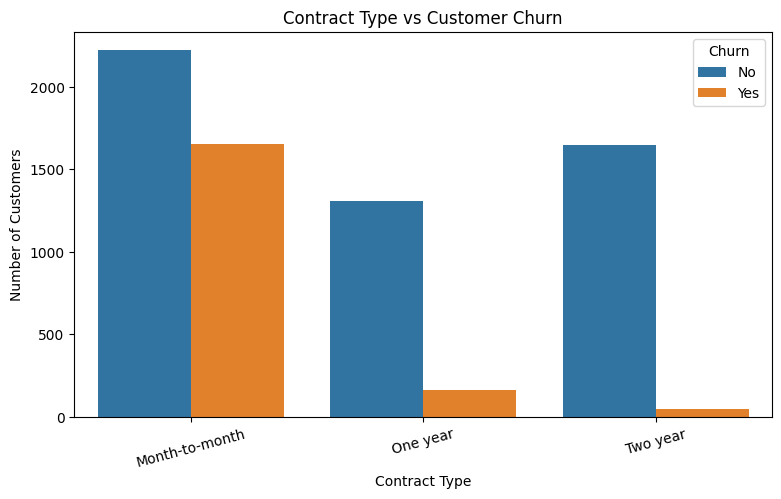

In [180]:
#Contract Type Analysis
plt.figure(figsize=(9, 5))

sns.countplot(
    data=churn_data,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

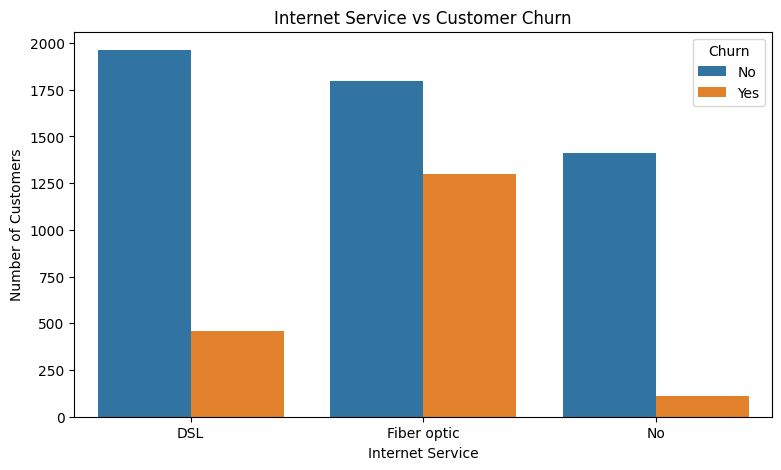

In [181]:
#Internet service analysis
plt.figure(figsize=(9, 5))

sns.countplot(
    data=churn_data,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

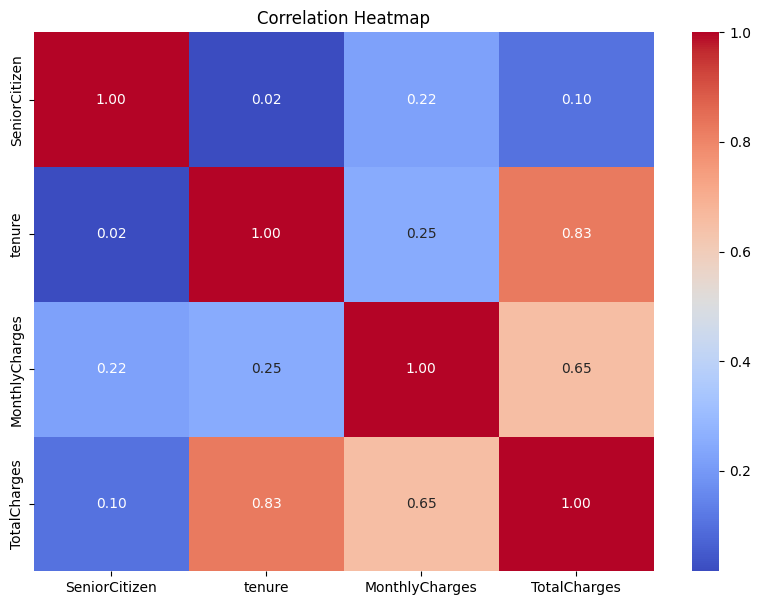

In [182]:
#Correlation Analysis
numeric_data = churn_data.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

**Prepare Features and Target**

In [183]:
# Drop customerID because it is an identifier, not a useful predictive feature
churn_data =churn_data.drop(columns=["customerID"], errors="ignore")

# Separate features and target
X = churn_data.drop(columns=["Churn"])
y = churn_data["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Ensure target conversion succeeded
assert y.notna().all(), "Unexpected target values found."

y = y.astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


**Split the Dataset**

In [184]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


**Preprocess Numerical and Categorical Features**

In [185]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("\nPreprocessing pipeline created successfully!")

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully!


**Apply Preprocesing**

In [186]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing completed!")
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)


Preprocessing completed!
Training data shape: (5634, 45)
Testing data shape: (1409, 45)


**Build Multiple Machine Learning Models**

In [187]:
from scipy.sparse import issparse

#define the classifieres

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric="logloss"
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}


In [188]:
results = []
trained_models = {}


#Train and evaluate the models

for name, model in classifiers.items():

    print("\n" + "=" * 55)
    print(f"Training: {name}")
    print("=" * 55)

    # Gaussian Naive Bayes requires dense input
    if isinstance(model, GaussianNB):

        X_train_input = (
            X_train_processed.toarray()
            if issparse(X_train_processed)
            else np.asarray(X_train_processed)
        )

        X_test_input = (
            X_test_processed.toarray()
            if issparse(X_test_processed)
            else np.asarray(X_test_processed)
        )

    else:
        X_train_input = X_train_processed
        X_test_input = X_test_processed

    # Train the classifier
    model.fit(X_train_input, y_train)

    # Predict churn
    y_pred = model.predict(X_test_input)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Display evaluation results
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    # Store trained classifier
    trained_models[name] = model




Training: Logistic Regression
Accuracy:  0.7381
Precision: 0.5043
Recall:    0.7834
F1 Score:  0.6136

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Training: Gaussian Naive Bayes
Accuracy:  0.6948
Precision: 0.4589
Recall:    0.8369
F1 Score:  0.5928

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.64      0.76      1035
           1       0.46      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409


Training: Support Vector Machine
Accuracy:  0.7438
Precision: 0.5115
Recall:    0.7727
F1 

In [189]:

#Compare all classifiers


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON RESULTS")
display(results_df)

#Identify best model

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)
print("Best F1 Score:", results_df.loc[0, "F1 Score"])


MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
0,Support Vector Machine,0.743790,0.511504,0.772727,0.615548
1,Logistic Regression,0.738112,0.504303,0.783422,0.613613
2,Gaussian Naive Bayes,0.694819,0.458944,0.836898,0.592803
3,XGBoost,0.784244,0.605422,0.537433,0.569405
4,K-Nearest Neighbors,0.763662,0.552699,0.574866,0.563565
5,Random Forest,0.782115,0.618375,0.467914,0.532725



Best Model: Support Vector Machine
Best F1 Score: 0.6155484558040468


**Hyper Parameter Tuning**

In [190]:
# Hyperparameter tuning
# Random Forest, SVM, and XGBoost
from sklearn.base import clone#Creating Fresh copy of  preprocessor
from sklearn.model_selection import RandomizedSearchCV
print("Starting Hyperparameter Tuning...")


# Random forest tuning

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ))
])

rf_params = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [None, 10, 15, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nTuning Random Forest...")

rf_search.fit(X_train, y_train)

best_rf_pipeline = rf_search.best_estimator_

print("\nBest Random Forest Parameters:")
print(rf_search.best_params_)

print(
    "Best Random Forest CV F1-score:",
    round(rf_search.best_score_, 4)
)



# 2. SVM Tuning


svm_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", SVC(
        class_weight="balanced"
    ))
])

svm_params = {
    "classifier__C": [0.1, 0.5, 1, 2, 5, 10, 20],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_params,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nTuning SVM...")

svm_search.fit(X_train, y_train)

best_svm_pipeline = svm_search.best_estimator_

print("\nBest SVM Parameters:")
print(svm_search.best_params_)

print(
    "Best SVM CV F1-score:",
    round(svm_search.best_score_, 4)
)



# 3. XGBOOST Tuning


xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ))
])

xgb_params = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [3, 4, 5, 6, 8],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nTuning XGBoost...")

xgb_search.fit(X_train, y_train)

best_xgb_pipeline = xgb_search.best_estimator_

print("\nBest XGBoost Parameters:")
print(xgb_search.best_params_)

print(
    "Best XGBoost CV F1-score:",
    round(xgb_search.best_score_, 4)
)

print("\nAll three models have been tuned!")

Starting Hyperparameter Tuning...

Tuning Random Forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Random Forest Parameters:
{'classifier__n_estimators': 500, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2', 'classifier__max_depth': 10}
Best Random Forest CV F1-score: 0.638

Tuning SVM...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best SVM Parameters:
{'classifier__kernel': 'rbf', 'classifier__gamma': 0.01, 'classifier__C': 0.1}
Best SVM CV F1-score: 0.6199

Tuning XGBoost...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best XGBoost Parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.8}
Best XGBoost CV F1-score: 0.5932

All three models have been tuned!


**Model comparison**

In [191]:
#Compare tuned models
tuned_models = {
    "Tuned Random Forest": best_rf_pipeline,
    "Tuned SVM": best_svm_pipeline,
    "Tuned XGBoost": best_xgb_pipeline
}

comparison_results = []

for model_name, model in tuned_models.items():

    print("\nEvaluating:", model_name)

    # Predict using original, unprocessed test data
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })


# Create comparison table
tuned_results_df = pd.DataFrame(comparison_results)

tuned_results_df = tuned_results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n========== TUNED MODEL COMPARISON ==========")

display(tuned_results_df.round(4))


Evaluating: Tuned Random Forest

Evaluating: Tuned SVM

Evaluating: Tuned XGBoost

========== TUNED MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Random Forest,0.7637,0.5400,0.7406,0.6246
1,Tuned SVM,0.7268,0.4910,0.8048,0.6099
2,Tuned XGBoost,0.8098,0.6779,0.5401,0.6012


**Display Bset tunned model**

In [192]:
#Identify best tuned model

best_model_name = tuned_results_df.iloc[0]["Model"]

final_model = tuned_models[best_model_name]

print("\n========== BEST TUNED MODEL ==========")

print("Model:", best_model_name)

print(
    "Accuracy:",
    round(tuned_results_df.iloc[0]["Accuracy"], 4)
)

print(
    "Precision:",
    round(tuned_results_df.iloc[0]["Precision"], 4)
)

print(
    "Recall:",
    round(tuned_results_df.iloc[0]["Recall"], 4)
)

print(
    "F1 Score:",
    round(tuned_results_df.iloc[0]["F1 Score"], 4)
)


========== BEST TUNED MODEL ==========
Model: Tuned Random Forest
Accuracy: 0.7637
Precision: 0.54
Recall: 0.7406
F1 Score: 0.6246


**Classificatin Report**

In [193]:


final_predictions = final_model.predict(X_test)

print("\n CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        final_predictions,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)


 CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.89      0.77      0.83      1035
       Churn       0.54      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



**Confusion Matrix**

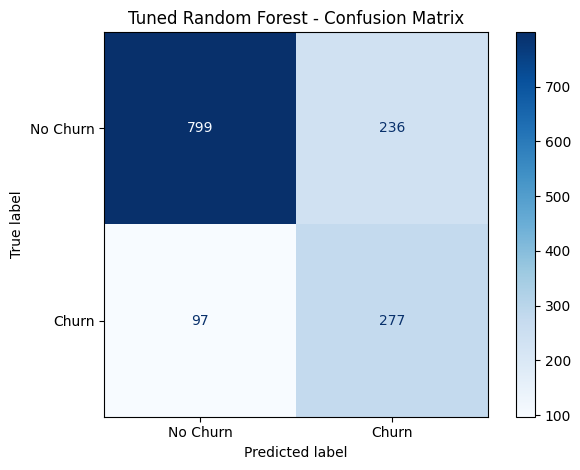

In [194]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=[0, 1],
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title(f"{best_model_name} - Confusion Matrix")
plt.tight_layout()
plt.show()

**Save the final model**

In [195]:
joblib.dump(
    final_model,
    "customer_churn_model.pkl"
)

print("\nFinal model saved successfully!")
print("File: customer_churn_model.pkl")
print("Selected model:", best_model_name)


Final model saved successfully!
File: customer_churn_model.pkl
Selected model: Tuned Random Forest


**Test the saved model**

In [206]:


# Load the saved model
loaded_model = joblib.load("customer_churn_model.pkl")

# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict customer churn
prediction = loaded_model.predict(sample_customer)[0]

# Get the actual churn value for the same customer
actual = y_test.iloc[0]

# Display the prediction
if prediction == 1:
    print("Prediction: Customer is likely to churn.")
else:
    print("Prediction: Customer is likely to stay.")

# Display the actual result
print("Actual churn value:", actual)

if actual == 1:
    print("Actual result: Customer churned.")
else:
    print("Actual result: Customer did not churn.")

# Check whether the prediction is correct
if prediction == actual:
    print("Prediction status: Correct prediction!")
else:
    print("Prediction status: Incorrect prediction.")


    print("Actual result: Customer did not churn.")

Prediction: Customer is likely to stay.
Actual churn value: 0
Actual result: Customer did not churn.
Prediction status: Correct prediction!
